# DT2470 Tempo Estimation
## Jupyter Notebook for development and visualisation purposes

In [1]:
import matplotlib.pyplot as plt
from scipy import signal
import soundfile as sf
import numpy as np

params = {'legend.fontsize': 'x-large','figure.figsize': (15, 6),
         'axes.labelsize': 'x-large','axes.titlesize':'x-large',
         'xtick.labelsize':'x-large','ytick.labelsize':'x-large'}
plt.rcParams.update(params)

Fs = 44100
Data.shape = (1325095, 2)
Length = 30.048 s


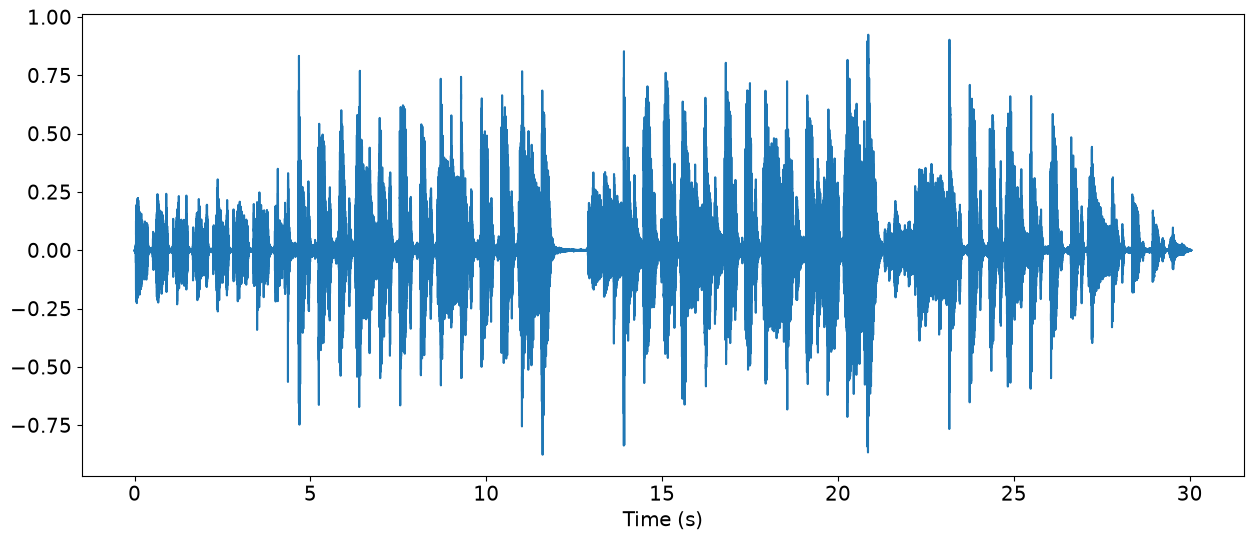

In [2]:
# using a arbitrarily chosen soundfile without vocals for dev purposes
data, sampleRate = sf.read('results\demucs_pilot\Albums-Ballroom_Magic-15\instrumental.wav')
print(f'Fs = {sampleRate}')
print(f'Data.shape = {data.shape}')

if data.shape[-1] >= 2:
    # data = data[:, 0]
    data = np.mean(data, axis=1)

timeLength = data.size/sampleRate
print(f'Length = {timeLength:.3f} s')
timeAxis = np.linspace(0, timeLength, data.size)
plt.plot(timeAxis, data); plt.xlabel("Time (s)")
plt.show()

### Onset Detection
Using spectral based novelty, according to the following steps:
1. STFT
2. Log-compression
3. Differentiation
4. Accumulation along frequencies
5. Normalize by subtracting moving average

#### STFT

In [3]:
windowLen = int(50/1000 * sampleRate)
windowOverlap = int(25/1000 * sampleRate)
freq, time, Z = signal.stft(data, sampleRate, nperseg=windowLen, noverlap=windowOverlap)
magnitude = np.abs(Z)
# eps = 1e-6 
# ZdB = 20 * (np.log10(np.maximum(magnitude, eps)) - np.log10(np.max(magnitude))) 

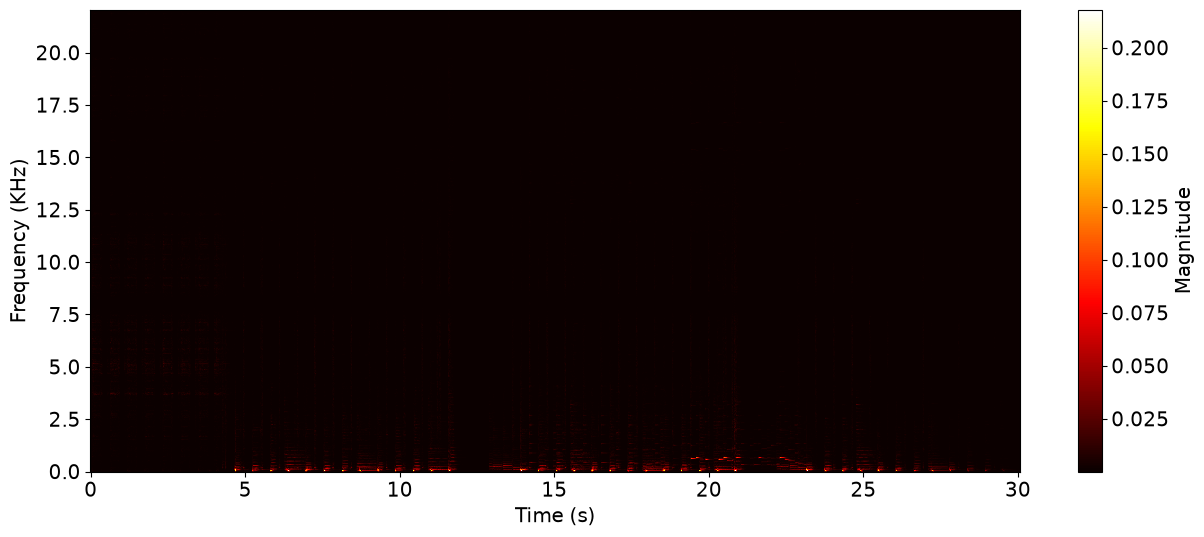

In [4]:
plt.pcolormesh(time, freq/1000, magnitude, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Log-Compression

In [5]:
# Eq. (6.5)
GAMMA = 1000
magCompressed = np.log(1 + GAMMA * magnitude)

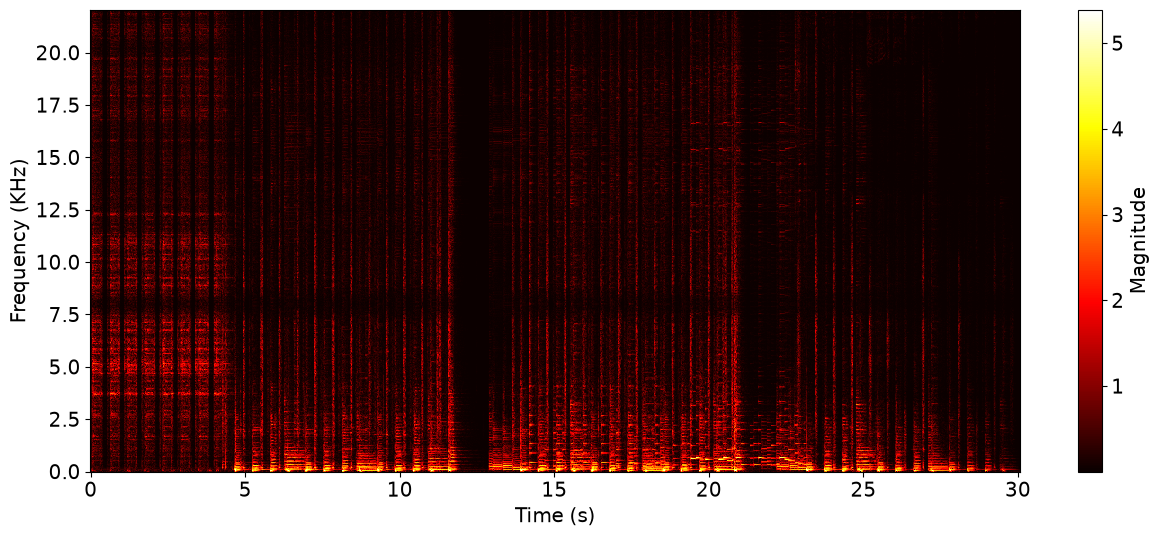

In [6]:
plt.pcolormesh(time, freq/1000, magCompressed, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Differentiation

In [7]:
# Eq. (6.6)
print(magCompressed.shape)

diff = np.diff(magCompressed, n=1, axis=1)
diff[diff<0] = 0

(1103, 1203)


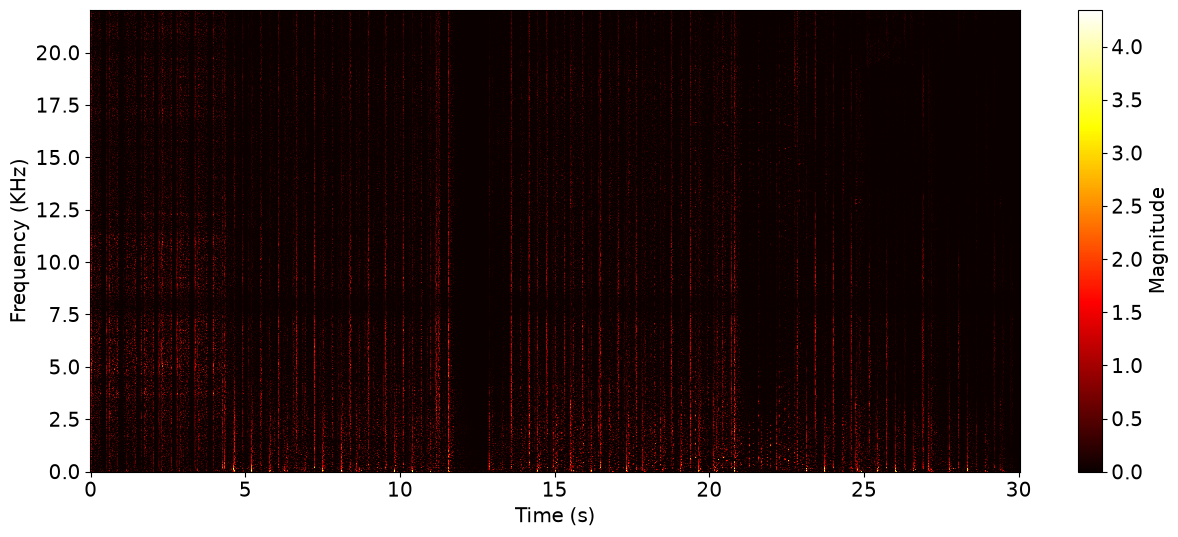

In [8]:
plt.pcolormesh(time[:-1], freq/1000, diff, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Accumulation

In [9]:
# also Eq. (6.6), just the summation over frequencies
novelty = np.sum(diff, axis=0)
FsNovelty = sampleRate / (windowLen - windowOverlap)
print(novelty.shape)

(1202,)


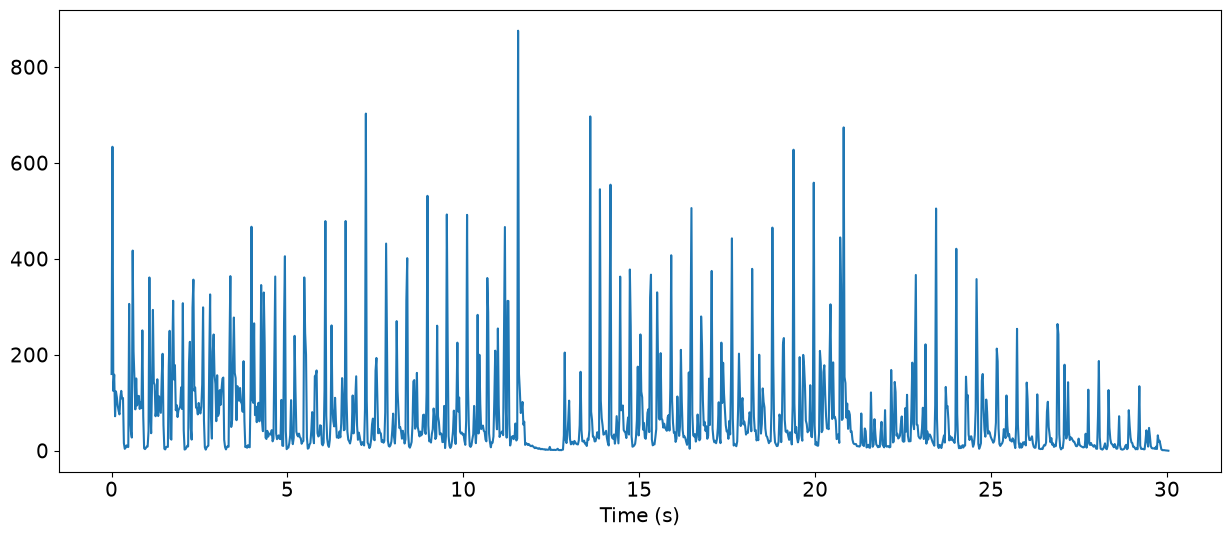

In [10]:
plt.plot(time[:-1], novelty); 
plt.xlabel("Time (s)"); plt.show()

#### Normalization

In [11]:
# Eq. (6.7) & (6.8)
def compute_local_average(x, M):
    """Compute local average of signal

    Notebook: C6/C6S1_NoveltySpectral.ipynb

    Args:
        x (np.ndarray): Signal
        M (int): Determines size (2M+1) in samples of centric window  used for local average

    Returns:
        local_average (np.ndarray): Local average signal
    """
    L = len(x)
    local_average = np.zeros(L)
    for m in range(L):
        a = max(m - M, 0)
        b = min(m + M + 1, L)
        local_average[m] = (1 / (2 * M + 1)) * np.sum(x[a:b])
    return local_average

MSec = 0.1
M = int(np.ceil(MSec * FsNovelty))

localAverage = compute_local_average(novelty, M)
novNormalised = novelty - localAverage
novNormalised[novNormalised < 0] = 0
novNormalised /= max(novNormalised)

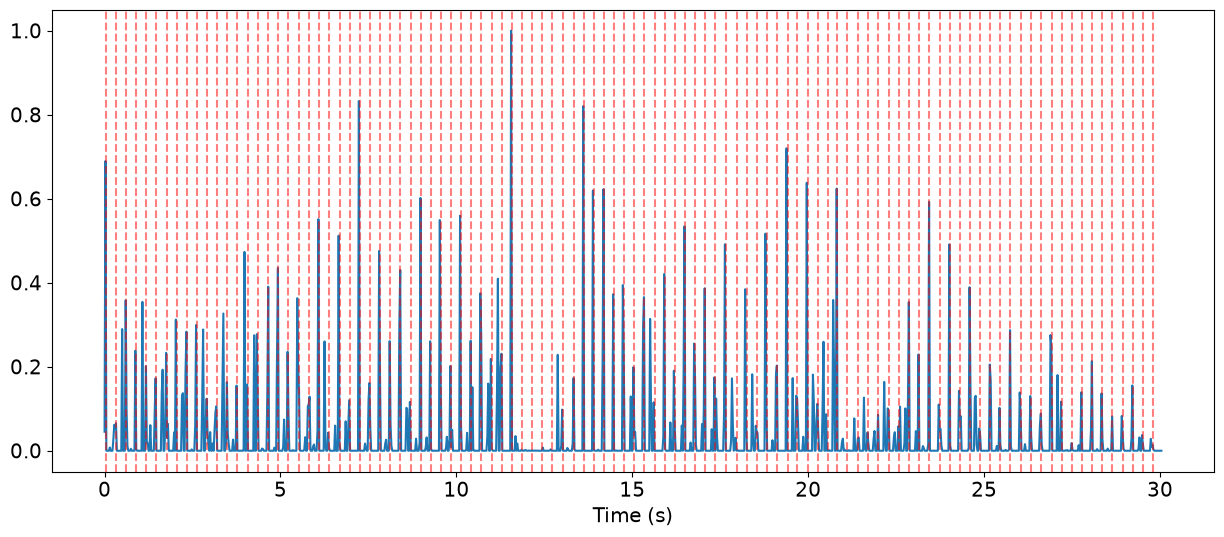

In [12]:
timeNov = np.arange(novelty.shape[0]) / FsNovelty
plt.plot(timeNov, novNormalised); 
plt.xlabel("Time (s)")

with open('data/ballroom/B_1.0/annotations/beats/Albums-Ballroom_Magic-15.beats') as f:
    for beat in f:
        beat = beat.split()[0]
        plt.axvline(float(beat), color='r', linestyle='--', alpha=0.5)

plt.show()

### Tempograms


The tempogram functions live in `tempo_estimation.py` so that the notebook and the
full experiment use exactly the same code. They take the novelty curve from above
(`novNormalised`, `FsNovelty`) as input.

Each column of a tempogram describes one 8-second window of the song. Bright rows
show tempi that fit the onsets well in that window.

In [13]:
import csv
import tempo_estimation as te

# Reference tempo for the song loaded above
trackId = 'Albums-Ballroom_Magic-15'
with open('data/ballroom/metadata.csv') as f:
    refBpm = next(float(r['reference_bpm']) for r in csv.DictReader(f) if r['track_id'] == trackId)
print('Reference tempo:', refBpm, 'BPM')

bpmAxis = te.BPM_AXIS

Reference tempo: 208.0 BPM


#### Fourier tempogram
Compares the novelty curve with sinusoids, one per tempo. Tends to light up
harmonics, i.e. 2x and 3x the true tempo.

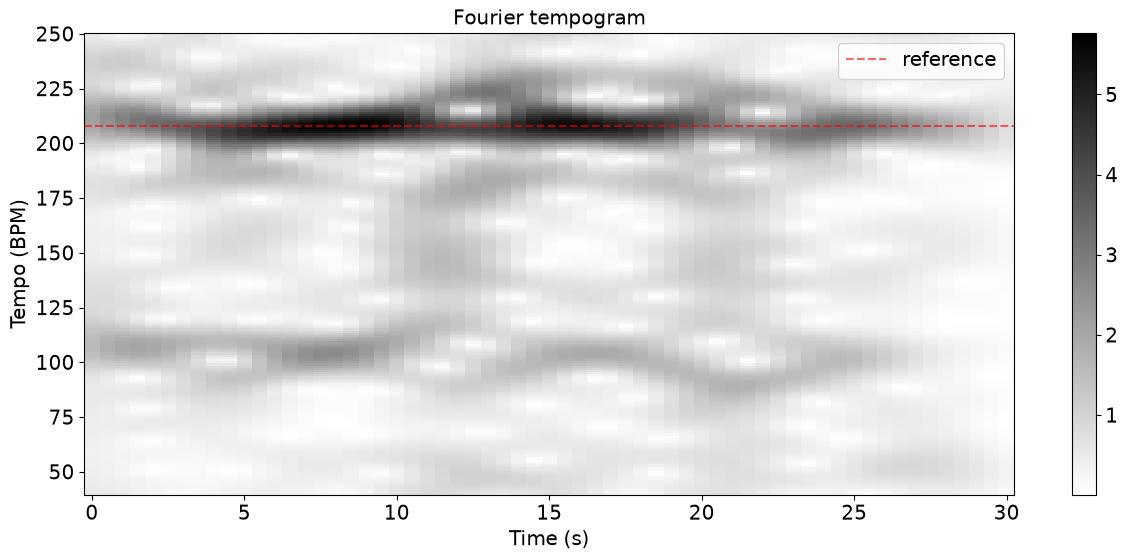

In [14]:
tempogramF = te.tempogram_fourier(novNormalised, FsNovelty)
timeT = np.arange(tempogramF.shape[1]) * te.TEMPO_HOP_SEC

plt.pcolormesh(timeT, bpmAxis, tempogramF, cmap='gray_r')
plt.axhline(refBpm, color='r', linestyle='--', alpha=0.6, label='reference')
plt.xlabel('Time (s)'); plt.ylabel('Tempo (BPM)'); plt.title('Fourier tempogram')
plt.legend(); plt.colorbar(); plt.show()

#### Autocorrelation tempogram
Compares the novelty curve with delayed copies of itself. Tends to light up
subharmonics, i.e. 1/2 and 1/3 of the true tempo.

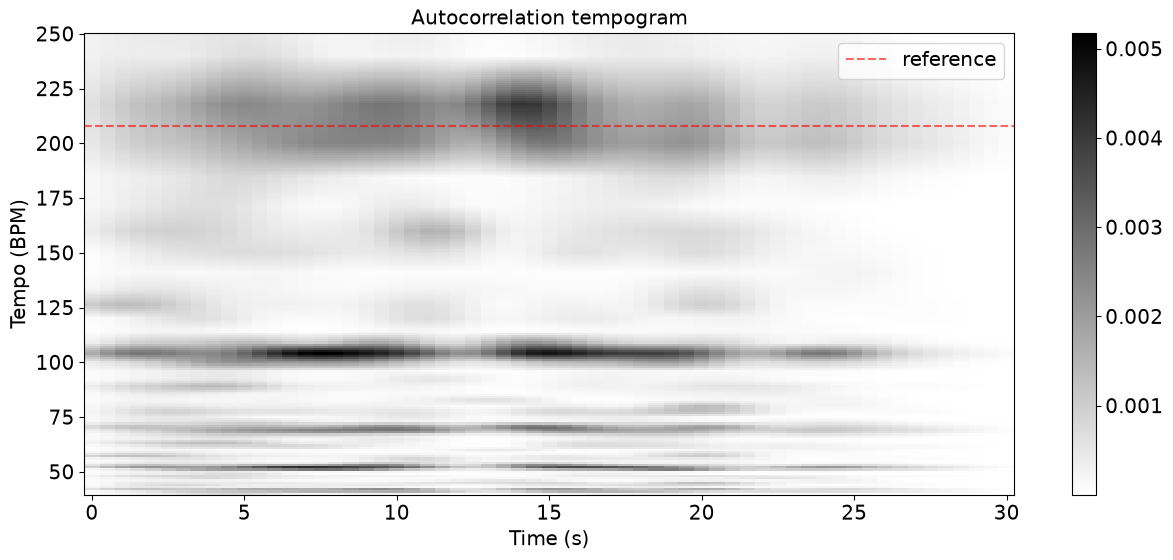

In [15]:
tempogramA = te.tempogram_autocorr(novNormalised, FsNovelty, window_type='hanning')

plt.pcolormesh(timeT, bpmAxis, tempogramA, cmap='gray_r')
plt.axhline(refBpm, color='r', linestyle='--', alpha=0.6, label='reference')
plt.xlabel('Time (s)'); plt.ylabel('Tempo (BPM)'); plt.title('Autocorrelation tempogram')
plt.legend(); plt.colorbar(); plt.show()

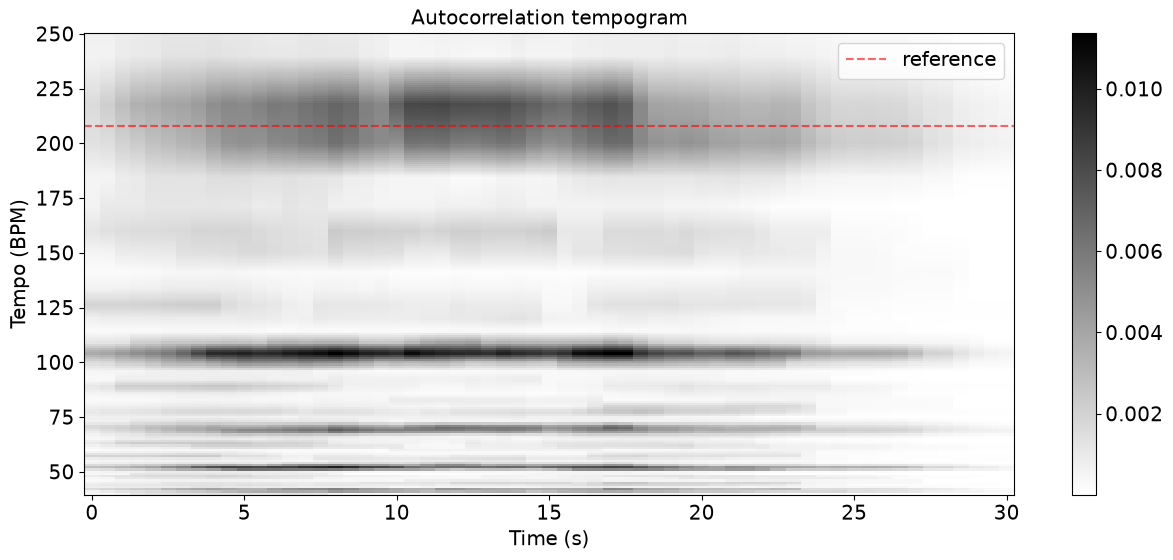

In [16]:
tempogramAB = te.tempogram_autocorr(novNormalised, FsNovelty, window_type='rect')

plt.pcolormesh(timeT, bpmAxis, tempogramAB, cmap='gray_r')
plt.axhline(refBpm, color='r', linestyle='--', alpha=0.6, label='reference')
plt.xlabel('Time (s)'); plt.ylabel('Tempo (BPM)'); plt.title('Autocorrelation tempogram')
plt.legend(); plt.colorbar(); plt.show()

### Global tempo
Average each tempogram over time into one curve. The *combined* curve is the product
of the two: Fourier's harmonics and autocorrelation's subharmonics cancel, and peaks
both agree on remain. A weak prior around 120 BPM (std one octave) breaks remaining ties.

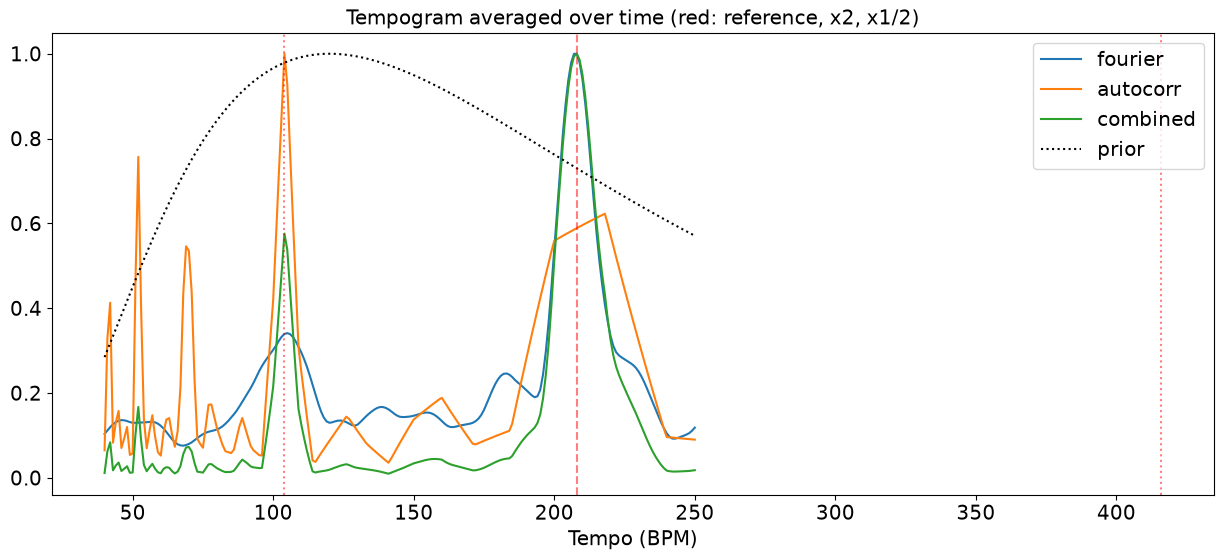

Estimated w Prior 207.518 BPM, Estimated w/o Prior 207.518 BPM, reference 208.0 BPM
{'abs_error': 0.4820706389530187, 'within 4.0% of ref': True, 'within 4.0% of ref octaves': True}


In [17]:
for method in ["fourier", "autocorr", "combined"]:
    plt.plot(bpmAxis, te.global_tempo_curve(novNormalised, FsNovelty, method), label=method)
plt.plot(bpmAxis, te.tempo_prior(), 'k:', label='prior')
for f, style in [(1, '--'), (2, ':'), (0.5, ':')]:
    plt.axvline(refBpm * f, color='r', linestyle=style, alpha=0.5)
plt.xlabel('Tempo (BPM)'); plt.title('Tempogram averaged over time (red: reference, x2, x1/2)')
plt.legend(); plt.show()

estBpm1, _ = te.estimate_tempo_from_novelty(novNormalised, FsNovelty, use_prior=True)
estBpm2, _ = te.estimate_tempo_from_novelty(novNormalised, FsNovelty, use_prior=False)
print(f'Estimated w Prior {estBpm1:.3f} BPM, Estimated w/o Prior {estBpm2:.3f} BPM, reference {refBpm} BPM')
print(te.evaluate(estBpm1, refBpm))

Sanity check: the module's `compute_novelty` follows the same steps and
parameters as the cells above, so it should give the same curve.

In [18]:
novModule, fsModule = te.compute_novelty(data, sampleRate)
print('Same novelty as notebook:', np.allclose(novModule, novNormalised), fsModule == FsNovelty)

Same novelty as notebook: True True


### Original vs. instrumental for one song with vocals
The same pipeline on the original excerpt and on the Demucs instrumental.
Requires `scripts/prepare_dataset.py` to have been run.

In [ ]:
from ballroom_dataset import get_development_set

development = get_development_set()
track = next(t for t in development if t.human_vocals == 'yes')
print(track.track_id, track.dance_style, 'reference', track.reference_bpm, 'BPM')

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, (label, path) in zip(axes, [('original', track.original_path),
                                     ('instrumental', track.instrumental_path)]):
    audio, sr = te.load_audio(path)
    nov, fsNov = te.compute_novelty(audio, sr)
    est, curve = te.estimate_tempo_from_novelty(nov, fsNov)
    ax.plot(bpmAxis, curve)
    ax.axvline(track.reference_bpm, color='r', linestyle='--', alpha=0.6)
    ax.set_title(f'{label}: estimated {est:.1f} BPM, abs. error {abs(est - track.reference_bpm):.1f}')
axes[1].set_xlabel('Tempo (BPM)')
plt.tight_layout(); plt.show()

FileNotFoundError: Missing C:\Users\vikto\.vscode\projects\dt2470\project\data\ballroom\separated\Albums-AnaBelen_Veneo-03\instrumental.wav. Run scripts/prepare_dataset.py locally.

### Whole set
Run from the terminal (prints a summary per dance style and saves a CSV in `results/`):

```bash
uv run --locked python tempo_estimation.py --split development
uv run --locked python tempo_estimation.py --split test
```